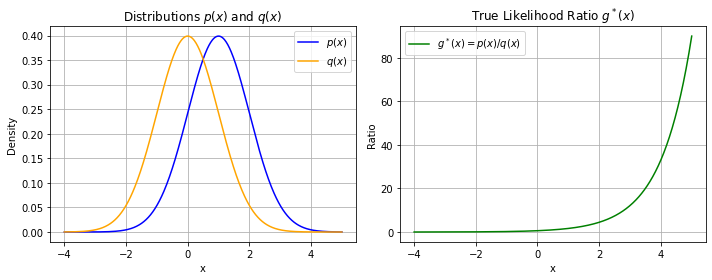

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
import os

# Step 1: Define true distributions
mu_p, mu_q, sigma = 1.0, 0.0, 1.0
p = lambda x: norm.pdf(x, loc=mu_p, scale=sigma)
q = lambda x: norm.pdf(x, loc=mu_q, scale=sigma)
g_true = lambda x: p(x) / q(x)

# Generate synthetic training samples
n_p, n_q = 300, 300
X_p = np.random.normal(mu_p, sigma, size=n_p)
X_q = np.random.normal(mu_q, sigma, size=n_q)

# Evaluate densities and ratio for plotting
x_grid = np.linspace(-4, 5, 500)
p_vals = p(x_grid)
q_vals = q(x_grid)
g_vals = g_true(x_grid)

# Plot p(x), q(x)
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(x_grid, p_vals, label='$p(x)$', color='blue')
plt.plot(x_grid, q_vals, label='$q(x)$', color='orange')
plt.title('Distributions $p(x)$ and $q(x)$')
plt.xlabel('x')
plt.ylabel('Density')
plt.legend()
plt.grid(True)

# Plot true ratio g*(x)
plt.subplot(1, 2, 2)
plt.plot(x_grid, g_vals, label='$g^*(x) = p(x)/q(x)$', color='green')
plt.title('True Likelihood Ratio $g^*(x)$')
plt.xlabel('x')
plt.ylabel('Ratio')
plt.legend()
plt.grid(True)

plt.tight_layout()
os.makedirs("../results", exist_ok=True)
plt.savefig("../results/LLR_example.png", dpi=300, bbox_inches='tight')
plt.show()

In [2]:
from sklearn.metrics.pairwise import rbf_kernel

# Step 2: RKHS setup
def compute_kernel_matrices(X_p, X_q, sigma):
    """Compute K_PP and K_QP using RBF kernel."""
    gamma = 1.0 / (2 * sigma ** 2)
    K_PP = rbf_kernel(X_p[:, np.newaxis], X_p[:, np.newaxis], gamma=gamma)
    K_QP = rbf_kernel(X_q[:, np.newaxis], X_p[:, np.newaxis], gamma=gamma)
    return K_PP, K_QP

# Loss function for optimization
def rkhs_loss(alpha, K_PP, K_QP, lambda_reg):
    """
    Compute the variational loss:
    L(α) = E_Q[ĝ] - E_P[log ĝ] + (λ/2) * αᵀ K_PP α
    where ĝ(x) = K(x, X_p) @ α
    """
    n_p = K_PP.shape[0]
    n_q = K_QP.shape[0]
    g_q = K_QP @ alpha
    g_p = K_PP @ alpha
    g_p = np.clip(g_p, 1e-8, None)

    term_q = np.mean(g_q)
    term_p = -np.mean(np.log(g_p))
    reg = 0.5 * lambda_reg * (alpha @ K_PP @ alpha)

    loss = term_q + term_p + reg
    return loss

# Also compute gradient (optional for optimizers like L-BFGS-B)
def rkhs_loss_grad(alpha, K_PP, K_QP, lambda_reg):
    n_p = K_PP.shape[0]
    n_q = K_QP.shape[0]
    g_p = K_PP @ alpha
    g_p = np.clip(g_p, 1e-8, None)

    grad_term_q = np.mean(K_QP, axis=0)
    grad_term_p = -(K_PP @ (1.0 / g_p)) / n_p
    grad_reg = lambda_reg * (K_PP @ alpha)

    grad = grad_term_q + grad_term_p + grad_reg
    return grad

# Example kernel computation
sigma = 1.0
K_PP, K_QP = compute_kernel_matrices(X_p, X_q, sigma)
alpha0 = np.ones(X_p.shape[0]) / X_p.shape[0]

# Show example loss value
lambda_reg = 1e-2
example_loss = rkhs_loss(alpha0, K_PP, K_QP, lambda_reg)
example_grad = rkhs_loss_grad(alpha0, K_PP, K_QP, lambda_reg)

example_loss, example_grad[:5]  # show loss and first 5 gradient entries


(1.046916853022589,
 array([-0.55421017, -0.53663435, -0.08614571, -0.70391913, -0.68536904]))

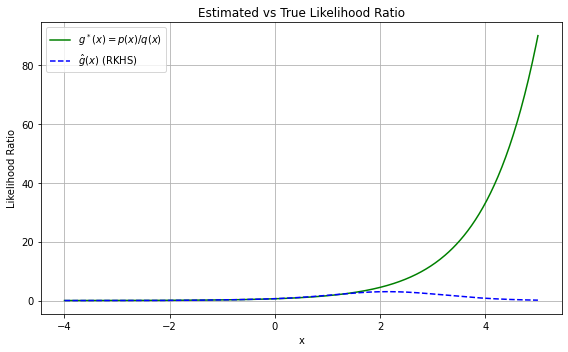

In [3]:
from scipy.optimize import minimize

# Step 3: Solve for optimal alpha
def fit_rkhs_estimator(X_p, X_q, sigma=1.0, lambda_reg=1e-2):
    K_PP, K_QP = compute_kernel_matrices(X_p, X_q, sigma)
    n_p = X_p.shape[0]
    alpha0 = np.ones(n_p) / n_p
    bounds = [(0, None)] * n_p  # alpha_i ≥ 0 for all i

    result = minimize(
        fun=lambda alpha: rkhs_loss(alpha, K_PP, K_QP, lambda_reg),
        x0=alpha0,
        jac=lambda alpha: rkhs_loss_grad(alpha, K_PP, K_QP, lambda_reg),
        method='L-BFGS-B',
        bounds=bounds,
        options={'maxiter': 1000, 'ftol': 1e-9}
    )

    if not result.success:
        raise RuntimeError("Optimization failed: " + result.message)

    return result.x, K_PP

# Fit the estimator
alpha_opt, K_PP = fit_rkhs_estimator(X_p, X_q, sigma=1.0, lambda_reg=1e-2)

# Evaluate the estimated ĝ(x) on a grid
def predict_g_hat(x_vals, X_p, alpha, sigma):
    gamma = 1.0 / (2 * sigma ** 2)
    K_xp = rbf_kernel(x_vals[:, np.newaxis], X_p[:, np.newaxis], gamma=gamma)
    return K_xp @ alpha

# Plot estimated vs true g(x)
x_grid = np.linspace(-4, 5, 500)
g_hat_vals = predict_g_hat(x_grid, X_p, alpha_opt, sigma)
g_true_vals = g_true(x_grid)

plt.figure(figsize=(8, 5))
plt.plot(x_grid, g_true_vals, label='$g^*(x) = p(x)/q(x)$', color='green')
plt.plot(x_grid, g_hat_vals, label='$\hat{g}(x)$ (RKHS)', linestyle='--', color='blue')
plt.xlabel("x")
plt.ylabel("Likelihood Ratio")
plt.title("Estimated vs True Likelihood Ratio")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

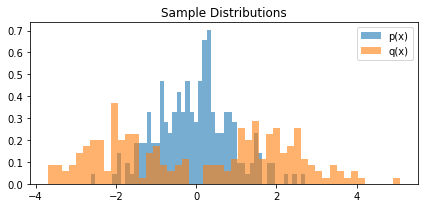

✅ Optimization succeeded. Final loss: -0.05526515599533732


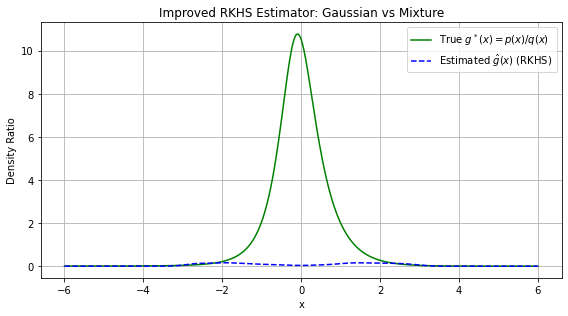

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from sklearn.metrics.pairwise import rbf_kernel

# 1. Define data distributions
def sample_p(n):
    return np.random.normal(loc=0.0, scale=1.0, size=n)

def sample_q(n):
    mix = np.random.rand(n) < 0.5
    samples = np.zeros(n)
    samples[mix] = np.random.normal(loc=-2.0, scale=0.8, size=np.sum(mix))
    samples[~mix] = np.random.normal(loc=2.0, scale=1.0, size=n - np.sum(mix))
    return samples

def g_true(x):
    p = np.exp(-0.5 * x**2) / np.sqrt(2 * np.pi)
    q = 0.5 * np.exp(-0.5 * ((x + 2)/0.8)**2) / (0.8 * np.sqrt(2 * np.pi)) + \
        0.5 * np.exp(-0.5 * ((x - 2)/1.0)**2) / (1.0 * np.sqrt(2 * np.pi))
    return p / q

# 2. RKHS estimation functions
def compute_kernel_matrices(X_p, X_q, sigma):
    gamma = 1.0 / (2 * sigma ** 2)
    return rbf_kernel(X_p[:, None], X_p[:, None], gamma=gamma), rbf_kernel(X_q[:, None], X_p[:, None], gamma=gamma)

def rkhs_loss(alpha, K_PP, K_QP, lambda_reg):
    return 0.5 * alpha @ (K_PP @ alpha) - np.mean(K_QP @ alpha) + 0.5 * lambda_reg * np.sum(alpha ** 2)

def rkhs_loss_grad(alpha, K_PP, K_QP, lambda_reg):
    return K_PP @ alpha - np.mean(K_QP, axis=0) + lambda_reg * alpha

def fit_rkhs_estimator(X_p, X_q, sigma=0.3, lambda_reg=1e-4):
    K_PP, K_QP = compute_kernel_matrices(X_p, X_q, sigma)
    n_p = X_p.shape[0]
    alpha0 = np.ones(n_p) / n_p
    bounds = [(0, None)] * n_p

    result = minimize(
        fun=lambda alpha: rkhs_loss(alpha, K_PP, K_QP, lambda_reg),
        x0=alpha0,
        jac=lambda alpha: rkhs_loss_grad(alpha, K_PP, K_QP, lambda_reg),
        method='L-BFGS-B',
        bounds=bounds,
        options={'maxiter': 2000, 'ftol': 1e-9}
    )

    if not result.success:
        print("⚠️ Optimization failed:", result.message)
    else:
        print("✅ Optimization succeeded. Final loss:", result.fun)

    return result.x, K_PP

def predict_g_hat(x_vals, X_p, alpha, sigma):
    gamma = 1.0 / (2 * sigma ** 2)
    K_xp = rbf_kernel(x_vals[:, None], X_p[:, None], gamma=gamma)
    return K_xp @ alpha

# 3. Run experiment
np.random.seed(42)
X_p = sample_p(200)
X_q = sample_q(200)

# Check coverage
plt.figure(figsize=(6, 3))
plt.hist(X_p, bins=50, alpha=0.6, label='p(x)', density=True)
plt.hist(X_q, bins=50, alpha=0.6, label='q(x)', density=True)
plt.legend(); plt.title("Sample Distributions"); plt.tight_layout(); plt.show()

# Fit estimator
sigma = 0.3
lambda_reg = 1e-4
alpha_opt, _ = fit_rkhs_estimator(X_p, X_q, sigma, lambda_reg)

# Evaluate on grid
x_grid = np.linspace(-6, 6, 500)
g_hat_vals = predict_g_hat(x_grid, X_p, alpha_opt, sigma)
g_true_vals = g_true(x_grid)

# Plot result
plt.figure(figsize=(8, 4.5))
plt.plot(x_grid, g_true_vals, label='True $g^*(x) = p(x)/q(x)$', color='green')
plt.plot(x_grid, g_hat_vals, label='Estimated $\hat{g}(x)$ (RKHS)', linestyle='--', color='blue')
plt.xlabel("x")
plt.ylabel("Density Ratio")
plt.title("Improved RKHS Estimator: Gaussian vs Mixture")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


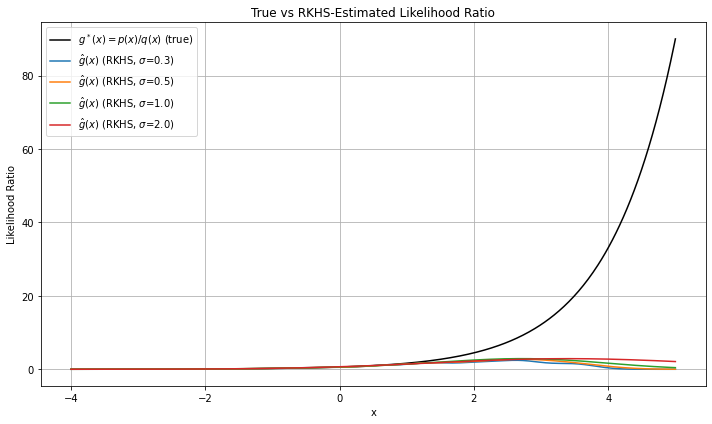

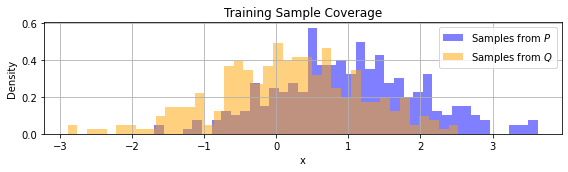

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from sklearn.metrics.pairwise import rbf_kernel
from scipy.optimize import minimize

# 1. Define true distributions
mu_p, mu_q, sigma_true = 1.0, 0.0, 1.0
p = lambda x: norm.pdf(x, loc=mu_p, scale=sigma_true)
q = lambda x: norm.pdf(x, loc=mu_q, scale=sigma_true)
g_true = lambda x: p(x) / q(x)

# 2. Generate training samples
n_p = n_q = 300
X_p = np.random.normal(mu_p, sigma_true, size=n_p)
X_q = np.random.normal(mu_q, sigma_true, size=n_q)

# 3. Define helper functions
def compute_kernel_matrices(X_p, X_q, sigma):
    gamma = 1.0 / (2 * sigma ** 2)
    K_PP = rbf_kernel(X_p[:, np.newaxis], X_p[:, np.newaxis], gamma=gamma)
    K_QP = rbf_kernel(X_q[:, np.newaxis], X_p[:, np.newaxis], gamma=gamma)
    return K_PP, K_QP

def rkhs_loss(alpha, K_PP, K_QP, lambda_reg):
    g_q = K_QP @ alpha
    g_p = np.clip(K_PP @ alpha, 1e-8, None)
    term_q = np.mean(g_q)
    term_p = -np.mean(np.log(g_p))
    reg = 0.5 * lambda_reg * (alpha @ K_PP @ alpha)
    return term_q + term_p + reg

def rkhs_loss_grad(alpha, K_PP, K_QP, lambda_reg):
    g_p = np.clip(K_PP @ alpha, 1e-8, None)
    grad_q = np.mean(K_QP, axis=0)
    grad_p = -(K_PP @ (1.0 / g_p)) / K_PP.shape[0]
    grad_reg = lambda_reg * (K_PP @ alpha)
    return grad_q + grad_p + grad_reg

def fit_rkhs_estimator(X_p, X_q, sigma=1.0, lambda_reg=1e-2):
    K_PP, K_QP = compute_kernel_matrices(X_p, X_q, sigma)
    n = X_p.shape[0]
    alpha0 = np.ones(n) / n
    bounds = [(0, None)] * n

    result = minimize(
        fun=lambda alpha: rkhs_loss(alpha, K_PP, K_QP, lambda_reg),
        x0=alpha0,
        jac=lambda alpha: rkhs_loss_grad(alpha, K_PP, K_QP, lambda_reg),
        method='L-BFGS-B',
        bounds=bounds,
        options={'maxiter': 1000, 'ftol': 1e-9}
    )
    if not result.success:
        raise RuntimeError("Optimization failed: " + result.message)

    return result.x

def predict_g_hat(x_vals, X_p, alpha, sigma):
    gamma = 1.0 / (2 * sigma ** 2)
    K_xp = rbf_kernel(x_vals[:, np.newaxis], X_p[:, np.newaxis], gamma=gamma)
    return K_xp @ alpha

# 4. Evaluate on grid
x_grid = np.linspace(-4, 5, 500)
g_true_vals = g_true(x_grid)

# 5. Plot RKHS estimates for various kernel widths
plt.figure(figsize=(10, 6))
plt.plot(x_grid, g_true_vals, label='$g^*(x) = p(x)/q(x)$ (true)', color='black')

for sigma in [0.3, 0.5, 1.0, 2.0]:
    alpha_opt = fit_rkhs_estimator(X_p, X_q, sigma=sigma, lambda_reg=1e-2)
    g_hat_vals = predict_g_hat(x_grid, X_p, alpha_opt, sigma)
    plt.plot(x_grid, g_hat_vals, label=fr'$\hat{{g}}(x)$ (RKHS, $\sigma$={sigma})')

plt.xlabel("x")
plt.ylabel("Likelihood Ratio")
plt.title("True vs RKHS-Estimated Likelihood Ratio")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# 6. Plot sample coverage
plt.figure(figsize=(8, 2.5))
plt.hist(X_p, bins=40, alpha=0.5, label='Samples from $P$', color='blue', density=True)
plt.hist(X_q, bins=40, alpha=0.5, label='Samples from $Q$', color='orange', density=True)
plt.title("Training Sample Coverage")
plt.xlabel("x")
plt.ylabel("Density")
plt.legend()
plt.grid(True)
plt.tight_layout()
os.makedirs("../results", exist_ok=True)
plt.savefig("../results/LLR_RKHS_estimation_example.png", dpi=300, bbox_inches='tight')
plt.show()
